In [1]:
import pandas as pd 
import numpy as np
from sklearn.preprocessing import StandardScaler,RobustScaler
from sklearn.impute import SimpleImputer,KNNImputer,KNNImputer
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import accuracy_score, recall_score, f1_score


In [2]:


df = pd.read_csv("stroke_zaj1.csv",sep=';')


## dane intro 

- response variable to stroke

In [3]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67,0,1,Yes,Private,Urban,"228,69","36,6",formerly smoked,1
1,Male,80,0,1,Yes,Private,Rural,"105,92","32,5",never smoked,1
2,Female,49,0,0,Yes,Private,NaN,"171,23","34,4",smokes,1
3,Female,79,1,0,Yes,Self-employed,Rural,"174,12",24,never smoked,1
4,Male,81,0,0,Yes,Private,Urban,"186,21",29,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
607,Male,48,0,0,Yes,Private,Rural,NaN,"34,6",never smoked,0
608,Female,62,0,0,Yes,Private,Urban,"60,2","27,7",formerly smoked,0
609,Male,69,1,0,No,NaN,Urban,"75,95","28,6",never smoked,0
610,Female,54,0,0,Yes,Private,Urban,"75,09","38,9",formerly smoked,0


In [4]:
df.shape



(612, 11)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   gender             612 non-null    str  
 1   age                612 non-null    int64
 2   hypertension       612 non-null    int64
 3   heart_disease      612 non-null    int64
 4   ever_married       612 non-null    str  
 5   work_type          557 non-null    str  
 6   Residence_type     552 non-null    str  
 7   avg_glucose_level  568 non-null    str  
 8   bmi                549 non-null    str  
 9   smoking_status     612 non-null    str  
 10  stroke             612 non-null    int64
dtypes: int64(4), str(7)
memory usage: 52.7 KB


In [6]:
df.describe()


,age,hypertension,heart_disease,stroke
count,612.000000,612.000000,612.000000,612.000000
mean,52.632353,0.158497,0.096405,0.341503
std,20.709916,0.365505,0.295388,0.474602
min,5.000000,0.000000,0.000000,0.000000
25%,39.000000,0.000000,0.000000,0.000000
50%,54.000000,0.000000,0.000000,0.000000
75%,70.000000,0.000000,0.000000,1.000000
max,82.000000,1.000000,1.000000,1.000000


In [7]:
 
for col in ["bmi", "avg_glucose_level"]: # zmiana na numeric ponieważ wcześniej te kolumny były wczytane jako string 
    df[col] = pd.to_numeric( 
        df[col].str.replace(",", ".", regex=False),
        errors="coerce"
    )

In [8]:
df.dtypes


gender                   str
age                    int64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object

In [9]:

df.isna().sum()



gender                0
age                   0
hypertension          0
heart_disease         0
ever_married          0
work_type            55
Residence_type       60
avg_glucose_level    44
bmi                  63
smoking_status        0
stroke                0
dtype: int64

In [10]:
df[df.duplicated()]

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke


- brak zduplikowanych pacjętów

## krótki opis danych


- Zbiór danych zawiera **612 obserwacji i 11 zmiennych**, z czego 10 to zmienne objaśniające, a `stroke` jest zmienną objaśnianą, określającą wystąpienie udaru mózgu.

- W zbiorze występują zmienne numeryczne (m.in. wiek, BMI, poziom glukozy), binarne (nadciśnienie, choroby serca) oraz kategoryczne (płeć, rodzaj pracy, miejsce zamieszkania, stan cywilny i status palenia).

- Średni wiek badanych wynosi około 52,6 lat, a **34,15% obserwacji dotyczy osób, u których wystąpił udar**. Brakujące wartości występują w czterech zmiennych: `work_type`, `Residence_type`, `avg_glucose_level` i `bmi`.

- Dodatkowo zmienne `bmi` i `avg_glucose_level` zostały przekonwertowane z typu tekstowego na numeryczny (`float64`), aby umożliwić ich dalszą analizę i imputację.



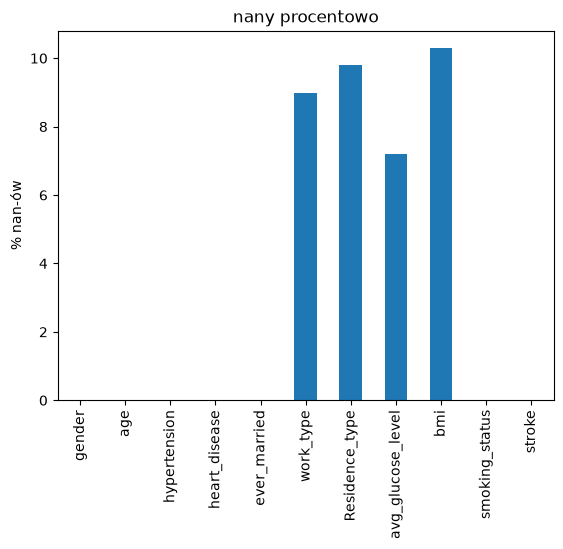

In [11]:
(df.isna().mean() * 100).round(2).plot(kind='bar') # y axis to są procenty 

plt.title("nany procentowo")

plt.ylabel("% nan-ów")

plt.show()

- Brakujące wartości występują w czterech zmiennych: `bmi` (10,3%), `Residence_type` (9,8%), `work_type` (9,0%) oraz `avg_glucose_level` (7,2%). 

- W pozostałych zmiennych nie odnotowano braków danych. Ze względu na stosunkowo niewielki udział braków zdecydowano się zastosować różne metody imputacji zamiast usuwać obserwacje.

## podzial danych 

In [12]:

X = df.drop(columns=["stroke"])
y = df["stroke"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,  test_size=0.2, random_state=42, stratify=y )

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

In [13]:

print(f"Test: ---> {y_train.value_counts(normalize=True)}  ") 

print(f"Test: ---> {y_test.value_counts(normalize=True)}  ")

Test: ---> stroke
0    0.658487
1    0.341513
Name: proportion, dtype: float64  
Test: ---> stroke
0    0.658537
1    0.341463
Name: proportion, dtype: float64  


- podział danych klasy y jest +- równy, dlatego używamy stratify ( bez niej proporcji podzialu nie kontrolujemy i będą split-dependent)

## Imputowanie zmiennych przed i po

In [14]:


def impute_data(X_train, X_test, method="median"):
    """
     - Funckja dod imputowania danych zamiast powtarzać kod 3 razy ręcznie 

    """
    
    train = X_train.copy()
    test = X_test.copy()
    
    num_cols = train.select_dtypes(include="number").columns.tolist()
    cat_cols = train.select_dtypes(exclude="number").columns.tolist()

    if method == "knn": # KNN + SKALOWANIE
        scaler = StandardScaler()

        train_scaled = scaler.fit_transform(train[num_cols])
        test_scaled = scaler.transform(test[num_cols])

        imputer = KNNImputer(n_neighbors=5) # HEURISTIC ASSUMPTION 

        train[num_cols] = scaler.inverse_transform( imputer.fit_transform(train_scaled) )
        
        test[num_cols] = scaler.inverse_transform( imputer.transform(test_scaled) )

    else: # PLAIN VANILLA  
        imputer = SimpleImputer(strategy=method)

        train[num_cols] = imputer.fit_transform(train[num_cols])
        test[num_cols] = imputer.transform(test[num_cols])

    # jesli istnieje jakas categorical to impute most frequent
    if cat_cols:
        cat_imputer = SimpleImputer(strategy="most_frequent")

        train[cat_cols] = cat_imputer.fit_transform(train[cat_cols])
        test[cat_cols] = cat_imputer.transform(test[cat_cols])

    return train, test

In [15]:
X_train_mean, X_test_mean = impute_data(
    X_train, X_test, method="mean"
)

# Mediana
X_train_median, X_test_median = impute_data(
    X_train, X_test, method="median"
)

# KNN
X_train_knn, X_test_knn = impute_data(
    X_train, X_test, method="knn"
)

In [16]:
datasets = {
    "Before": X_train,
    "Mean": X_train_mean,
    "Median": X_train_median,
    "KNN": X_train_knn
}

stats = pd.concat({
    name: data[num_cols].agg(
        ["mean", "median", "std", "min", "max", "skew","kurtosis"]
    ).T
    for name, data in datasets.items()
})

display(stats)

mean     median        std    min     max  \
Before age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  117.192193  96.100000  54.355124  55.39  271.74   
       bmi                 30.632877  29.400000   7.132330  14.60   56.60   
Mean   age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  117.192193  98.660000  52.485130  55.39  271.74   
       bmi                 30.632877  30.632877   6.749354  14.60   56.60   
Median age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  115.768793  96.100000  52.751709  55.39  271.74   
       bmi                 30.504294  29.400000   6.759887  14.60   56.60   
KNN    age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  117.625865  98.050000  53.047017  55.39  271.74   
       bmi                 30.589325  29.500000   6.842206  14.60   56.60   

                              skew  kurtosis  
Before age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.166858  0.079976  
       bmi                0.718962  0.525592  
Mean   age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.208073  0.303188  
       bmi                0.759395  0.935958  
Median age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.266812  0.371732  
       bmi                0.812519  0.971619  
KNN    age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.164328  0.156194  
       bmi                0.734535  0.777725

## rozkłady przed i po imputation

In [17]:

def compare_distributions(before, after):

    cols = ["bmi", "avg_glucose_level"]

    df = pd.concat([
        before[cols].assign(Method="Before"), after[cols].assign(Method="After KNN")
    ])

    df = df.melt(
        id_vars="Method", var_name="Variable", value_name="Value"
    )

    sns.displot(
        data=df,
        x="Value",
        hue="Method",
        col="Variable",
        kind="hist",
         kde=True, stat="density",
        common_norm=False,
        alpha=0.4,
         height=4,
        aspect=1.3,
         facet_kws={"sharex": False, "sharey": False}
    )
    
    plt.show()

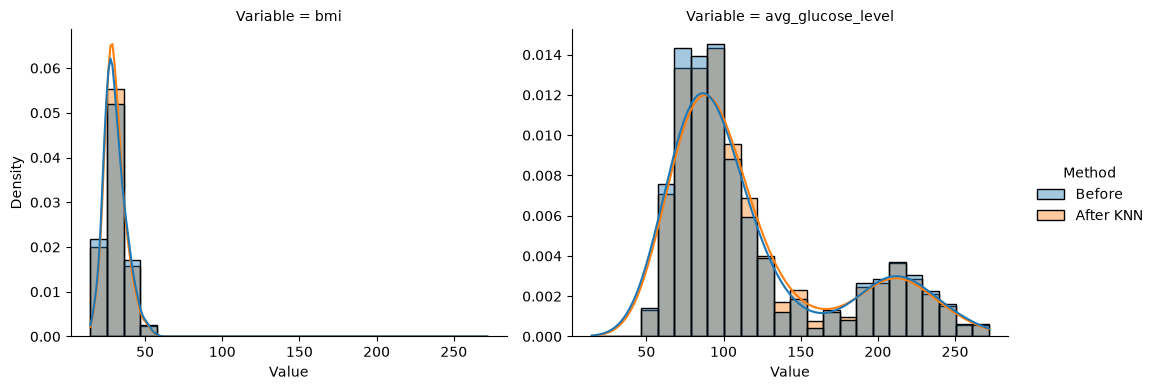

In [18]:
compare_distributions(X_train, X_train_knn)

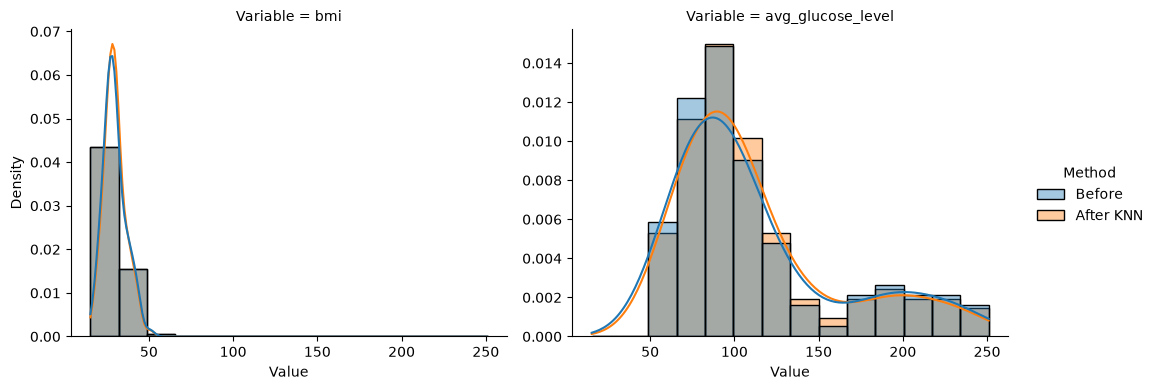

In [19]:
compare_distributions(X_test, X_test_knn)

Po imputacji rozkłady zmiennych ulegly niewielkim zmianom głownie dla BMI i średniego poziomu glukozy.

- Mean: zachowuje średnią, ale zmniejsza odchylenie standardowe.
- Median: zachowuje medianę, ale nieznacznie zmienia średnią oraz zwiększa skośność i kurtozę, szczególnie dla BMI.
- KNN: lepiej zachowuje zmienność danych i powoduje mniejsze zmiany skośności.

Ogólnie , zmiany w rozkładach były stosunkowo niewielkie. Na podstawie przedstawionych statystyk KNN najlepiej zachował charakterystyki oryginalnych rozkładów.

# Odpowiedz na pytania pomocnicze 

## 1

### Podział danych na zbiór uczący i testowy
- Train - służy do trenowania modelu.
- Test - służy do oceny modelu na nowych danych.
- Cel: -sprawdzenie zdolności modelu do generalizacji i ograniczenie ryzyka overfittingu. Najczęściej stosuje się podział 80/20 albo 70/30.


## 2

### Macierz błędu (Confusion Matrix)
Pokazuje liczbę poprawnych i błędnych klasyfikacji:
- TP – poprawnie wykryty udar.
- TN – poprawnie wykryty brak udaru.
- FP – fałszywy alarm.
- FN – niewykryty udar.

## 3

### Miary jakości klasyfikacji
- Accuracy – udział wszystkich poprawnych predykcji: (TP+TN)/(TP+TN+FP+FN).
- Sensitivity (Recall) – udział poprawnie wykrytych udarów: TP/(TP+FN).
- Specificity - udział poprawnie rozpoznanych osób bez udaru: TN/(TN+FP).
- Precision - udział rzeczywistych udarów wśród przewidzianych: TP/(TP+FP).
- F1-score - średnia harmoniczna Precision i Recall. 2 * precision * recall / ( precision + recall)
- ROC-AUC - zdolność modelu do rozróżniania klas przy różnych progach.

- Najważniejsza miara: w przypadku przewidywania udaru szczególnie istotna jest czułość (Recall), ponieważ niewykrycie udaru (FN) może mieć poważniejsze konsekwencje niż fałszywy alarm (FP).

# KNN 

In [20]:
X_test_knn

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
280,Male,39.0,0.0,0.0,Yes,Self-employed,Rural,88.480,34.30,never smoked
370,Male,63.0,0.0,0.0,Yes,Private,Rural,77.820,30.30,Unknown
557,Female,13.0,0.0,0.0,No,children,Rural,69.010,23.40,Unknown
117,Male,82.0,0.0,1.0,Yes,Govt_job,Rural,103.680,25.00,never smoked
21,Male,80.0,0.0,0.0,Yes,Self-employed,Rural,104.120,31.58,never smoked
...,...,...,...,...,...,...,...,...,...,...
192,Female,79.0,0.0,0.0,Yes,Private,Urban,97.730,21.50,smokes
88,Female,50.0,1.0,0.0,Yes,Private,Rural,73.180,30.30,formerly smoked
75,Female,57.0,0.0,0.0,No,Self-employed,Urban,68.020,37.50,never smoked
466,Male,80.0,0.0,0.0,Yes,Private,Rural,56.990,26.70,never smoked


In [21]:
X_train_knn

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
336,Male,42.0,0.0,0.0,Yes,Private,Urban,145.50,31.8,formerly smoked
427,Female,57.0,0.0,0.0,Yes,Private,Rural,93.85,29.1,never smoked
211,Male,40.0,0.0,0.0,Yes,Private,Rural,56.07,26.6,never smoked
483,Male,36.0,0.0,0.0,Yes,Private,Rural,106.85,40.1,never smoked
101,Female,58.0,0.0,0.0,Yes,Private,Rural,59.86,28.0,formerly smoked
...,...,...,...,...,...,...,...,...,...,...
509,Female,40.0,0.0,0.0,Yes,Private,Urban,153.24,38.2,Unknown
186,Male,49.0,0.0,0.0,No,Private,Urban,104.86,31.9,smokes
161,Male,70.0,1.0,0.0,Yes,Private,Rural,242.52,45.5,formerly smoked
570,Female,25.0,0.0,0.0,Yes,Private,Rural,90.65,20.9,Unknown


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV,RepeatedStratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [23]:


num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer(n_neighbors=5))
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

In [24]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier())
])

- bedziemy imputować w pipeline zeby unikać leakage 

In [25]:
param_grid = {
    "knn__n_neighbors": range(1, 31,2) # nieparzyste 
}

#cv = StratifiedKFold(
#    n_splits=5,
##    shuffle=True,
 #   random_state=42
#)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=42
)

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "f1": "f1"
    },
    refit="recall", #  DOSTAJEMY MAX RECALL 
    n_jobs=-1 # PARARELISM
)

grid.fit(X_train, y_train)

print("Best k:", grid.best_params_)
print("Best CV score:", grid.best_score_)

Best k: {'knn__n_neighbors': 13}
Best CV score: 0.577860962566845


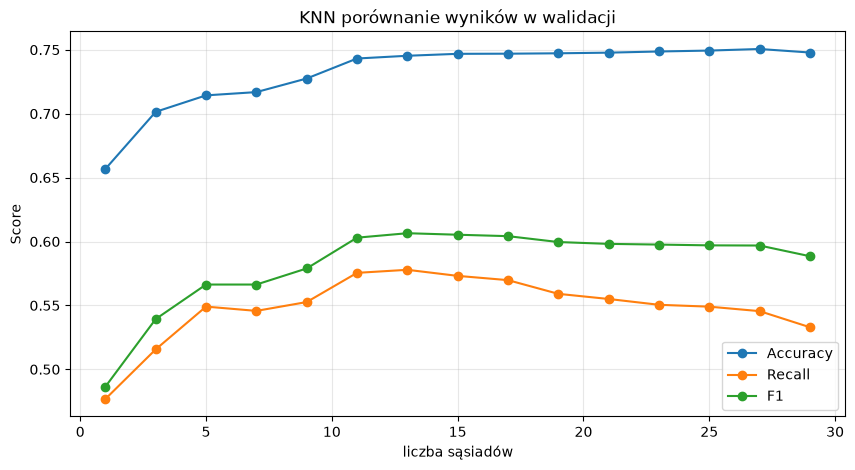

In [26]:

results = pd.DataFrame(grid.cv_results_)

metrics = [
    "mean_test_accuracy",
    "mean_test_recall",
    "mean_test_f1"
]

results.set_index("param_knn__n_neighbors")[metrics].plot(
    figsize=(10, 5),
    marker="o"
)

plt.xlabel("liczba sąsiadów")
plt.ylabel("Score")
plt.title("KNN porównanie wyników w walidacji")
plt.legend(["Accuracy", "Recall", "F1"])
plt.grid(alpha=0.3)
plt.show()

## test sample z poczatkowego tts

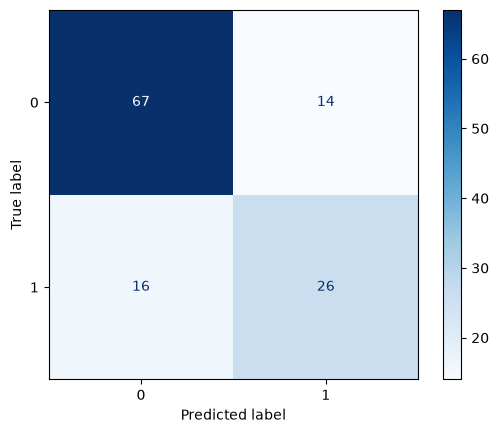

In [27]:

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues"
)

plt.show()

In [28]:
print(classification_report(y_test, y_pred)) 

              precision    recall  f1-score   support

           0       0.81      0.83      0.82        81
           1       0.65      0.62      0.63        42

    accuracy                           0.76       123
   macro avg       0.73      0.72      0.73       123
weighted avg       0.75      0.76      0.75       123



## odpowiedź na pytania teoretyczne 

## 1

- klasyfikuje nową obserwację na podstawie klas jej k najbliższych sąsiadów ze zbioru treningowego. Najczęściej wykorzystuje odległość euklidesową ( mozna równiez uzyc manhattan albo mińkowskiego), a klasa jest wybierana większością głosów.

- Przyklad : np chcemy zaklasyfikować owoc ( jablko vs malina ), i mamy 2 zmienne kruchość i słodkość, i jeśli dla nowej obserwacji zakładająć k = 5 ( 5 najbliższych sąsiadów) dostaniemy 3 glosy ( głosy w sensie sąsiadów) na jablko i 2 na maline, zakładająć podejście majority voting nowa obserwacja będzie zaklasyfikowana jako jabłko .


## 2


- k – liczba najbliższych sąsiadów branych pod uwagę podczas klasyfikacji nowej obserwacji.



- Małe k (np. 1, 3) – model jest bardziej wrażliwy na szum i wartości odstające, co zwiększa ryzyko overfittingu.

- Duże k (np. 15, 20) – model jest bardziej uogólniony, ale może prowadzić do underfittingu.

- Dobór k – najlepiej przeprowadzić walidację krzyżową (cross-validation) i wybrać wartość dającą najlepsze wyniki na podstawie wybranej metryki (np. Balanced Accuracy).

- Parzyste czy nieparzyste k? – przy klasyfikacji binarnej ( zakaldajc majority voting ) preferuje się nieparzyste k, ponieważ zmniejsza ryzyko remisu w głosowaniu. 

- Jesli wybierami majority voting , i dostaniemy remis mozemy przy remisie zastosować distance-based voring 1/d_i

- mozna użyć distance-based voring 1/d_i, zamiast rozpatrzywać niepatrzyste albo hybryde.

## 3

- standaryzacja jest zalecana ponieważ KNN najczęściej wykorzystuje odległość euklidesową. Bez standaryzacji zmienne o większej skali mogą dominować przy obliczaniu odległości, wpływając na to, które obserwacje zostaną uznane za najbliższych sąsiadów.

- jeśli mają podobne skale np ( 10 -12 ) oraz ( 9 -11) oraz zmienność standaryzacja moze nie byc konieczna.

## 4

- mozna wystarczy ze je przekształcimi uzywająć ONE-HOT albo Label encodingu.

- Z label należy uważać ponieważ narzuca on konkretne odległości między kategoriami. Np enkodowanie wykształcenie i załozenie ze d( podstawowe, srednie) oraz d( srednie, wyzsze) =1 , pytanie czy powinnismy zakladac ze dystans jest taki sam ?  

# KNN -WEIGHTED

- bierzemy ten sam preprocess pipeline

In [29]:
def gaussian_kernel(distances):
    h = np.maximum(distances.max(axis=1, keepdims=True), 1e-12)
    return np.exp(-0.5 * (distances / h)**2)

pipeline_kknn = Pipeline([
    ("preprocessor", preprocessor),
    ("kknn", KNeighborsClassifier(weights=gaussian_kernel))
])

In [30]:
param_grid_kknn = {
    "kknn__n_neighbors": range(1, 31)
}

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=42
)

grid_kknn = GridSearchCV(
    pipeline_kknn,
    param_grid_kknn,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "f1": "f1"
    },
    refit="recall",
    n_jobs=-1
)

grid_kknn.fit(X_train, y_train)

print("Best k:", grid_kknn.best_params_)
print("Best CV score:", grid_kknn.best_score_)

Best k: {'kknn__n_neighbors': 13}
Best CV score: 0.5811586452762924


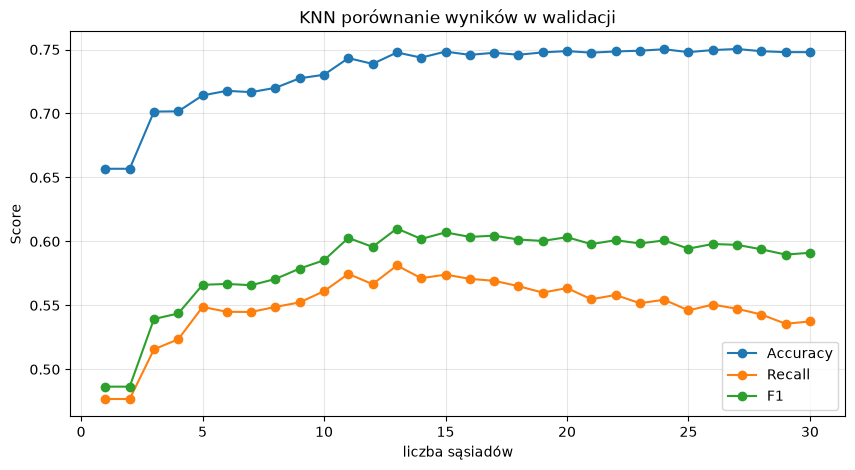

In [31]:

results = pd.DataFrame(grid_kknn.cv_results_)

metrics = [
    "mean_test_accuracy",
    "mean_test_recall",
    "mean_test_f1"
]

results.set_index("param_kknn__n_neighbors")[metrics].plot(
    figsize=(10, 5),
    marker="o"
)

plt.xlabel("liczba sąsiadów")
plt.ylabel("Score")
plt.title("KNN porównanie wyników w walidacji")
plt.legend(["Accuracy", "Recall", "F1"])
plt.grid(alpha=0.3)
plt.show()

In [32]:

comparison = pd.DataFrame({
    "KNN": [
        grid.cv_results_[f"mean_test_{m}"][grid.best_index_]
        for m in ["accuracy", "recall", "f1"]
    ],
    "KKNN": [
        grid_kknn.cv_results_[f"mean_test_{m}"][grid_kknn.best_index_]
        for m in ["accuracy", "recall", "f1"]
    ]
}, index=["Accuracy", "Recall","F1"])

display(comparison.round(4))

,KNN,KKNN
Accuracy,0.7453,0.7477
Recall,0.5779,0.5812
F1,0.6065,0.6101


- wyniki są do siebie dosyć podobne, na każdym poziomie metryki

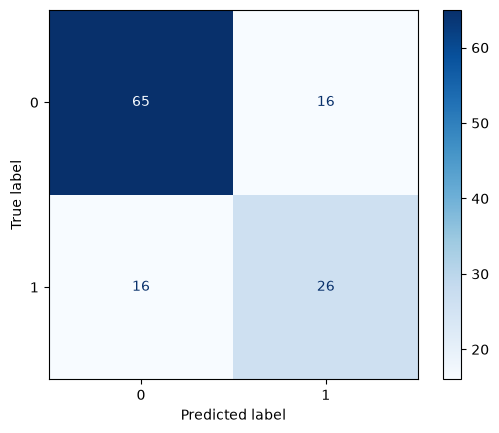

In [33]:
best_model = grid_kknn.best_estimator_

y_pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues"
)

plt.show()

In [43]:
print(classification_report(y_test, y_pred)) 

              precision    recall  f1-score   support

           0       0.79      0.79      0.79        81
           1       0.60      0.60      0.60        42

    accuracy                           0.72       123
   macro avg       0.69      0.69      0.69       123
weighted avg       0.72      0.72      0.72       123



## odpowiedź na pytania teoretyczne 

## 1

- wazone dystansy, dokladniej : 

KNN – każdy z k najbliższych sąsiadów ma taką samą wagę (majority voting).

KKNN – stosuje kernel, np. Gaussian, który przypisuje sąsiadom wagi zależne od odległości. Bliżsi sąsiedzi mają większy wpływ na wynik i vice versa.


## 2

- k nie musi byc nieparzyste w porównaniu do KNN.
- pozostałe ogracznia są te same a poza tym ma te same co KNN

# LOGISTYCZNA REGRESJA  

In [34]:
from sklearn.linear_model import LogisticRegression


In [35]:

pipeline_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("lr", LogisticRegression())
])

In [36]:
param_grid_lr = {
    "lr__C": np.logspace(-3, 3, 20) #im wieksza lambda, tym silniejsza regularyzacja 
}

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=42
)

grid_lr = GridSearchCV(
    pipeline_lr,
    param_grid_lr,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "f1": "f1"
    },
    refit="recall",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Best C:", grid_lr.best_params_)
print("Best CV Recall:", grid_lr.best_score_)

Best C: {'lr__C': np.float64(26.366508987303554)}
Best CV Recall: 0.6105080213903744


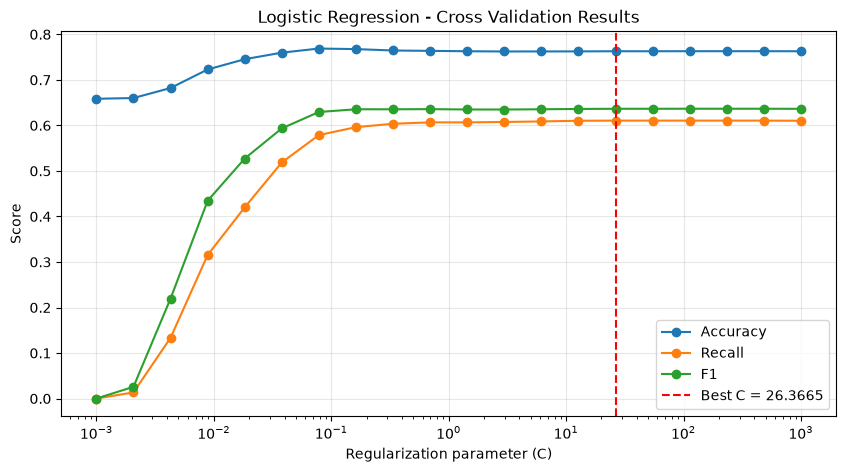

In [37]:

results_lr = pd.DataFrame(grid_lr.cv_results_)

metrics = [
    "mean_test_accuracy",
    "mean_test_recall",
    "mean_test_f1"
]

results_lr["C"] = results_lr["param_lr__C"].astype(float)

results_lr.set_index("C")[metrics].plot(
    figsize=(10, 5),
    marker="o"
)

best_C = grid_lr.best_params_["lr__C"]

plt.axvline(
    best_C,
    color="red",
    linestyle="--",
    label=f"Best C = {best_C:.4f}"
)

plt.xscale("log")
plt.xlabel("Regularization parameter (C)")
plt.ylabel("Score")
plt.title("Logistic Regression - Cross Validation Results")
plt.legend(["Accuracy", "Recall", "F1", f"Best C = {best_C:.4f}"])
plt.grid(alpha=0.3)
plt.show()

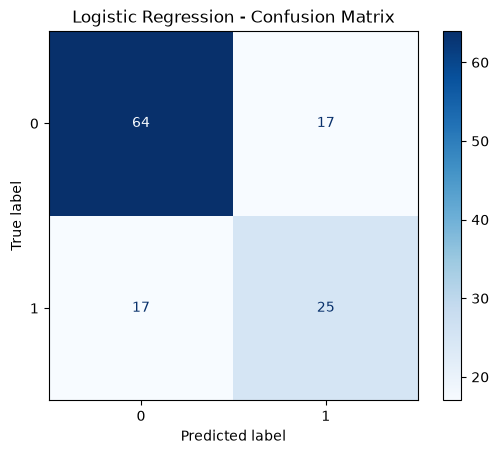

In [44]:
best_model_lr = grid_lr.best_estimator_

y_pred_lr = best_model_lr.predict(X_test)


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [45]:
print(classification_report(y_test, y_pred_lr))


              precision    recall  f1-score   support

           0       0.79      0.79      0.79        81
           1       0.60      0.60      0.60        42

    accuracy                           0.72       123
   macro avg       0.69      0.69      0.69       123
weighted avg       0.72      0.72      0.72       123



In [39]:

models = {
    "KNN": grid.best_estimator_,
    "KKNN": grid_kknn.best_estimator_,
    "Logistic Regression": grid_lr.best_estimator_
}

comparison = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred)
    })

comparison = pd.DataFrame(comparison)
display(comparison.round(4))

,Model,Accuracy,Recall,F1
0,KNN,0.7561,0.6190,0.6341
1,KKNN,0.7398,0.6190,0.6190
2,Logistic Regression,0.7236,0.5952,0.5952


- tutaj tabelka została policzona na podstawie Test_sample z pierwszego początkowego TTS.

- ponownie wyniki są między algorytmami dosyć podobne, są lekkie róznice w wszystkich 3 metrykach

- najgorszy wynuk F1 score osiąga LR , najlepszy KNN. Pod względem RECALL najlepszym algorytmem jest algorytm KNN.

## odpowiedź na pytania teoretyczne 


## 5. Interpretacja parametrów regresji logistycznej

Współczynniki $\beta_i$ określają wpływ zmiennych na log-odds wystąpienia zdarzenia.

$$
\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta^T X
$$

- $\beta_i > 0$ – wzrost zmiennej zwiększa prawdopodobieństwo wystąpienia zdarzenia.
- $\beta_i < 0$ – wzrost zmiennej zmniejsza prawdopodobieństwo wystąpienia zdarzenia.
- $\beta_i = 0$ – brak wpływu zmiennej w modelu.

Do interpretacji wykorzystujemy Odds Ratio (OR):

$$
OR = e^{\beta_i}
$$

- OR > 1 – wzrost szans wystąpienia zdarzenia.
- OR < 1 – spadek szans wystąpienia zdarzenia.
- OR = 1 – brak zmiany szans.

Przykład: jeśli $\beta_i = 0.5$, to $OR = e^{0.5} \approx 1.65$, czyli wzrost X o jednostkę zwiększa szanse wystąpienia zdarzenia o około 65%, ceteris paribus.

## 1. Założenia regresji logistycznej

- Zmienna zależna (y) – w regresji binarnej przyjmuje wartości 0 lub 1 (np. udar lub brak udaru).
- Liniowość  – zakładamy liniową zależność między zmiennymi a logarytmem ilorazu szans. tzn log( p /( 1 - p)) = w^T*x +b
- Brak silnego multicollineraity – zmienne objaśniające nie powinny być ze sobą zbyt mocno skorelowane.
- Brak idealnej separacji klas – zmienne nie powinny idealnie rozdzielać klas, ponieważ może to utrudniać estymację parametrów. ( bedize brak zbieżności Log-Likelihoodu, parametry będą dążyć od inf, ponieważ algorytm  MAX( Log-Likelihood)) 

- niezaleznosc obserwacji ( statystycznej) tzn. jedna obserwacja nie powinna wpływać na drugą ani dostarczać o niej informacji , ponieważ zaburzy to SE, co za tym idize P-value oraz przedialy ufnosci paramów. 

## 2. Zmienne kategoryczne

- Można je wykorzystać po zakodowaniu, np. przez One-Hot albo label Encoding.
- Dla zmiennych z naturalnym porządkiem można zastosować Ordinal Encoding.
- zeby nie miec perfect multicollineraity nalezy jednac wyrzucić jedną kategorie z każdej zmiennej kategorycznej .

## 3. Czy standaryzacja jest konieczna?

- Nie ponieważ regresja logistyczna nie wykorzystuje odległości tak jak KNN.
- Jest zalecana przy regularyzacji L1/L2, ponieważ zmienne o różnych skalach mogą być nierównomiernie karane.
- Może również przyspieszyć uczenie modelu ( Optymalizacje) numeryka który optymalizuję log-likelihood np ( Newton-Rhapson , albo SGD).

## 4. Czy wartości odstające mają wpływ?

- Tak wartości odstające mogą wpływać na współczynniki modelu i jego predykcje ( ogólnie optymalizacje).
- Regularyzacja moze ograniczyć ich wpływ, ale nie usuwa problemu całkowicie.

## interpretacja paramów

In [40]:
from statsmodels.formula.api import logit

In [41]:

df_sm = X_train_knn.copy()
df_sm["stroke"] = np.asarray(y_train)

num_cols = X_train_knn.select_dtypes(include="number").columns
cat_cols = X_train_knn.select_dtypes(exclude="number").columns

formula = "stroke ~ " + " + ".join(
    list(num_cols) + [f"C({col})" for col in cat_cols]
)

model_sm = logit(formula, data=df_sm).fit()

print(model_sm.summary())

Optimization terminated successfully.
         Current function value: 0.452414
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 stroke   No. Observations:                  489
Model:                          Logit   Df Residuals:                      474
Method:                           MLE   Df Model:                           14
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.2953
Time:                        21:41:13   Log-Likelihood:                -221.23
converged:                       True   LL-Null:                       -313.95
Covariance Type:            nonrobust   LLR p-value:                 5.068e-32
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                               -5.0405      0.9

- tutaj nie standaryzowalismy wiec regresje logistyczną intepretujemy klasycznie 


In [42]:

coef_df = pd.DataFrame({
    "Coefficient": model_sm.params,
    "Odds Ratio": np.exp(model_sm.params),
    "p-value": model_sm.pvalues
})


display(coef_df.round(4))

,Coefficient,Odds Ratio,p-value
Intercept,-5.0405,0.0065,0.0000
C(gender)[T.Male],0.1266,1.1350,0.6086
C(ever_married)[T.Yes],-0.3166,0.7286,0.4384
C(work_type)[T.Private],0.2111,1.2350,0.5648
C(work_type)[T.Self-employed],-0.3238,0.7234,0.4499
C(work_type)[T.children],1.2508,3.4930,0.3066
C(Residence_type)[T.Urban],0.0847,1.0884,0.7243
C(smoking_status)[T.formerly smoked],0.2333,1.2628,0.5362
C(smoking_status)[T.never smoked],-0.2766,0.7583,0.4382
C(smoking_status)[T.smokes],0.2636,1.3016,0.5213


- Na podstawie wyników regresji logistycznej można stwierdzić, że tylko dwie zmienne są istotne statystycznie na poziomie 5% (p-value < 0.05):

- Age (OR = 1.0841, p < 0.001) – wzrost wieku o 1 rok wiąże się ze wzrostem szans wystąpienia udaru o około 8,41%, ceteris paribus.

- Hypertension (OR = 2.0278, p = 0.0243) – osoby z nadciśnieniem mają około 2 razy większe szanse wystąpienia udaru niż osoby bez nadciśnienia, ceteris paribus.

- Pozostałe zmienne, takie jak BMI, poziom glukozy, płeć czy status palenia, nie są istotne statystycznie (p-value > 0.05). Nie ma więc wystarczających podstaw, aby potwierdzić ich związek z wystąpieniem udaru na podstawie tego modelu.

- Wyniki wskazują, że wiek i nadciśnienie są istotnie związane z wystąpieniem udaru.